# 05 LightGBM

trains lightgbm on the same shared features as xgboost and scores it in the same 25 week backtest. the model is refitted at every cutoff using only the data before it.

settings: 300 trees, learning rate 0.05, 63 leaves (roughly the same size as xgboost’s depth 6), no tuning. the target is raw sales and forecasts are clipped at 0.

caveat: lightgbm grows trees leaf by leaf and xgboost grows them level by level, so 63 leaves and depth 6 are close but not identical.

## Set-Up (Imports and Loading Data)

In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgbms

import sys
sys.path.append('../src')

from load_clean_data import load_clean_data
from backtest import get_cutoffs, split_data_by_cutoff, run_backtest
from baselines import add_all_baselines
from evaluation import score_forecasts, merge_backtests
from features import build_features, FEATURE_COLUMNS
from models import add_lgbm_forecast, LGBM_PARAMS, add_xgb_forecast

In [2]:
df = load_clean_data()
df_with_features = build_features(df)

## Train Test Split

In [3]:
train, test = split_data_by_cutoff(df_with_features, '2015-02-02', 7)

## Run LGBM (Single Cutoff)

In [4]:
results = add_lgbm_forecast(train, test, '2015-02-02')

In [5]:
print(len(results))
print(results['lgbm_forecast'].describe())

7805
count     7805.000000
mean      6897.353473
std       4031.054958
min          0.000000
25%       4965.102391
50%       7006.734257
75%       9149.214288
max      27422.356873
Name: lgbm_forecast, dtype: float64


### Compare against baselines

In [6]:
results = add_all_baselines(train, results, '2015-02-02')

results = add_xgb_forecast(train, results, '2015-02-02')

scores = score_forecasts(results, ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'lgbm_forecast', 'xgb_forecast'])

In [7]:
scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
xgb_forecast,1053.18,688.49,10.63%
avg_28d_baseline,1128.94,711.88,10.99%
naive_baseline,1098.63,711.96,10.99%
lgbm_forecast,1167.04,764.01,11.80%
avg_all_baseline,1261.37,887.79,13.71%


finding: at 2015-02-02 lightgbm scores 11.80%, behind xgboost (10.63%) and also behind the 28 day average and naive baselines (10.99%). it only beats the full history average (13.71%). this is one calm week, so it says little on its own, and the full backtest is the real test.

## Run LGBM (All Cutoffs)

In [8]:
FORECAST = False

if FORECAST:
    cutoffs = get_cutoffs(df['Date'].max(), 7)
    bt = run_backtest(df_with_features, cutoffs, 7, add_lgbm_forecast)

    bt = bt[['Store', 'Date', 'Sales', 'cutoff', 'day_ahead', 'lgbm_forecast']]

    bt.to_csv('../results/backtests/lgbm_backtest.csv', index=False, )

else: 
    bt = pd.read_csv('../results/backtests/lgbm_backtest.csv', parse_dates=['Date', 'cutoff'], low_memory=False)

In [9]:
SAVE_SCORES = True

if SAVE_SCORES:
    scores = score_forecasts(bt, ['lgbm_forecast'])
    scores.to_csv('../results/lgbm_scores.csv', index=False)

In [10]:
combined_bt = merge_backtests(['baselines', 'xgb', 'lgbm'])

forecasts = ['naive_baseline', 'avg_28d_baseline', 'avg_all_baseline', 'xgb_forecast', 'lgbm_forecast']

combined_scores = score_forecasts(combined_bt, forecasts)

model_names = {
    'naive_baseline': 'Naive Baseline',
    'avg_28d_baseline': '28-Day Average Baseline',
    'avg_all_baseline': 'Full History Average Baseline',
    'xgb_forecast': 'XGBoost Forecast', 
    'lgbm_forecast': 'LightGBM Forecast'
}

relabelled_scores = combined_scores.copy()
relabelled_scores['Model'] = relabelled_scores['Model'].replace(model_names)

relabelled_scores.sort_values(by='WAPE').style.hide(axis='index').format({ 'WAPE': '{:.2f}%' }, precision=2)

Model,RMSE,MAE,WAPE
XGBoost Forecast,1001.30,604.95,10.33%
LightGBM Forecast,1035.76,619.47,10.57%
Full History Average Baseline,2029.48,1261.49,21.53%
28-Day Average Baseline,2127.55,1326.10,22.63%
Naive Baseline,3206.68,2112.59,36.06%


finding: lightgbm scores 10.57% WAPE, very close to xgboost (10.33%) and about half the error of the best baseline (21.53%). RMSE is 1036 against 1001.

caveat: neither model is tuned and each was run once with one random seed, so a gap this small could change with tuning. the baselines also don’t see Promo or holidays, so the gap to them is not purely the algorithm (same caveat as notebook 04).

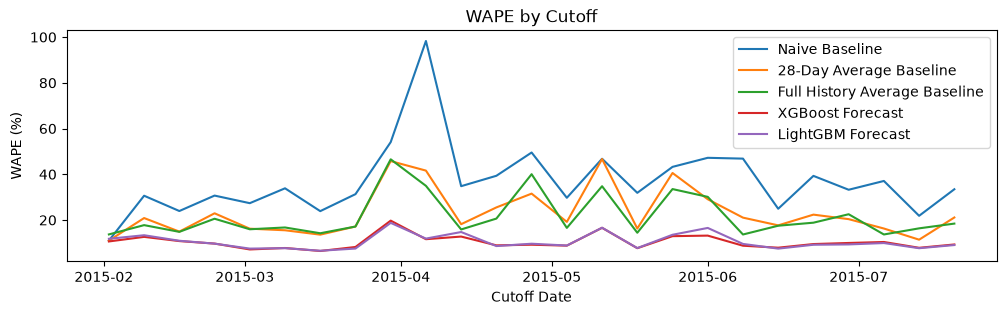

In [11]:
scores_by_cutoff = score_forecasts(combined_bt, forecasts, by='cutoff')

pivotted = scores_by_cutoff.pivot(index='cutoff', columns='Model', values='WAPE')

plt.figure(figsize=(12, 3))

for model in forecasts:
    plt.plot(pivotted.index, pivotted[model], label=model_names[model])

plt.title('WAPE by Cutoff')
plt.xlabel('Cutoff Date')
plt.ylabel('WAPE (%)')
plt.legend()

plt.show()

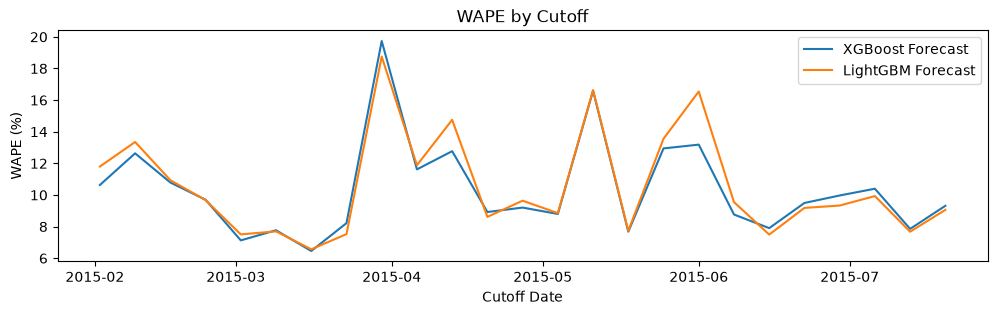

In [13]:
scores_by_cutoff = score_forecasts(combined_bt, ['xgb_forecast', 'lgbm_forecast'], by='cutoff')

pivotted = scores_by_cutoff.pivot(index='cutoff', columns='Model', values='WAPE')

plt.figure(figsize=(12, 3))

for model in ['xgb_forecast', 'lgbm_forecast']:
    plt.plot(pivotted.index, pivotted[model], label=model_names[model])

plt.title('WAPE by Cutoff')
plt.xlabel('Cutoff Date')
plt.ylabel('WAPE (%)')
plt.legend()

plt.show()

In [19]:
print((pivotted['lgbm_forecast'] > pivotted['xgb_forecast']).sum())

gap = pivotted['lgbm_forecast'] - pivotted['xgb_forecast']

print(gap.sort_values(ascending=False).head(3))

print(gap.sort_values().head(3))

14
cutoff
2015-06-01    3.358820
2015-04-13    1.984590
2015-02-02    1.166073
dtype: float64
cutoff
2015-03-30   -0.985383
2015-03-23   -0.694043
2015-06-29   -0.636427
dtype: float64


finding: lightgbm and xgboost track each other closely and struggle in the same weeks (end of march, mid may, start of june). lightgbm is worse in 14 of 25 weeks, but most of its pooled gap comes from 3 weeks (1 jun, 13 apr, 2 feb), which together add up to more than the whole difference. in the other weeks it is level with or slightly better than xgboost.

caveat: neither model is tuned and each was run once with one random seed, so the ranking could change after tuning. three weeks is also a thin basis for explaining the gap.